<a href="https://colab.research.google.com/github/BrandonOrtiz7/programas/blob/main/Brandon_Alexis_Ortiz_P%C3%A9rez_Clase_VC_Rademacher_Perdida_Incertidumbre_Explicado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio: dimensión VC, complejidad de Rademacher, pérdidas e incertidumbre

**Clase de fundamentos matemáticos con algoritmos de predicción (Google Colab).**

**Objetivos.** Al terminar podrás explicar qué significa que una clase de hipótesis «fragmenta» puntos; calcular la complejidad de Rademacher (no solo nombrarla); relacionarla con la pérdida y una cota de generalización; y distinguir esa garantía de la incertidumbre de una predicción.

**Ruta de aprendizaje:** 0. Preparación → 1. Dimensión VC → 2. Rademacher → 3. Predictores reales y sobreajuste → 4. Funciones de pérdida → 5. Cotas e incertidumbre estadística → 6. Incertidumbre predictiva → 7. Ejercicios.

**Notación.** $X$ son las entradas, $Y\in\{-1,+1\}$ o $\{0,1\}$ la etiqueta; $h\in\mathscr H$ es una regla de predicción; $S=\{(x_i,y_i)\}_{i=1}^n$ es una muestra i.i.d. (independiente e idénticamente distribuida).

## 0. Preparamos el laboratorio

Trabajaremos con modelos simples para poder **verificar exactamente** las definiciones, y después con árboles de decisión y regresión logística. Las semillas aleatorias hacen reproducibles las gráficas. El código usa bibliotecas ya disponibles en Colab.

In [ ]:
# Importamos itertools para enumerar todas las combinaciones posibles de etiquetas o signos.
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# La función sigmoide expit convierte una puntuación real en una probabilidad entre 0 y 1.
from scipy.special import expit
# Importamos árboles de decisión, cuyo nivel de profundidad regula su flexibilidad.
from sklearn.tree import DecisionTreeClassifier
# La regresión logística será nuestro segundo algoritmo probabilístico de comparación.
from sklearn.linear_model import LogisticRegression
# Estas métricas cuantifican el desempeño de clasificadores y sus probabilidades.
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss
# calibration_curve agrupa predicciones para analizar si sus probabilidades están calibradas.
from sklearn.calibration import calibration_curve

# Definimos una semilla fija para reproducir las mismas muestras aleatorias.
SEED = 2026
# Creamos un generador reproducible; cada llamada avanza su secuencia aleatoria.
rng = np.random.default_rng(SEED)
# Establecemos tamaño predeterminado de las figuras y estilo de la cuadrícula.
plt.rcParams.update({"figure.figsize": (9, 4.7), "axes.grid": True, "grid.alpha": .25})
# Limitamos a cuatro decimales la presentación de tablas (no los cálculos).
pd.set_option('display.precision', 4)
# Confirmamos visualmente que las importaciones se realizaron sin errores.
print('Preparación correcta: NumPy, scikit-learn y Matplotlib disponibles.')

Preparación correcta: NumPy, scikit-learn y Matplotlib disponibles.


## 1. Dimensión VC: ¿cuántos patrones de etiquetas puede representar un modelo?

Partimos de puntos ordenados en una recta. Definimos tres **clases de hipótesis** (no tres ajustes concretos):

- **Umbrales crecientes:** $h_t(x)=+1$ si $x\geq t$ y $-1$ en otro caso. El signo solo puede cambiar una vez y de $-1$ a $+1$.
- **Intervalos positivos:** $h_{a,b}(x)=+1$ si $a\leq x\leq b$; $-1$ fuera. Puede pasar de $-1$ a $+1$ y regresar a $-1$.
- **Todas las asignaciones posibles:** sobre $n$ entradas distintas pueden asignar cualquier combinación de $\pm1$. Es una clase de referencia de máxima flexibilidad.

**Fragmentar (*shatter*)** un conjunto de $n$ puntos significa poder producir sus **$2^n$ etiquetados** con miembros de $\mathscr H$. La **dimensión VC** es el mayor número de puntos que pueden fragmentarse, o infinito si no existe máximo.

⚠️ No es el número de parámetros ni el error de entrenamiento. Se refiere a lo que *puede representar toda la clase* en los peores puntos posibles.

In [ ]:
# Esta función enumera las predicciones de todos los umbrales crecientes sobre x.
def predicciones_umbral(x):
    # La cadena bajo la función resume lo que devuelve: una fila por hipótesis.
    """Filas = todas las reglas x>=t sobre los valores distintos observados."""
    # Convertimos la entrada a arreglo para usar operaciones vectorizadas.
    x = np.asarray(x)
    # Ordenamos los valores distintos: una frontera solo importa entre valores observados.
    valores = np.unique(x)
    # Construimos una matriz; cada fila será un patrón de etiquetas {-1,+1}.
    return np.array([
        # Marcamos como -1 los primeros k valores y como +1 todos los restantes.
        np.where(np.isin(x, valores[:k]), -1, +1)
        # Probamos k desde 0 (todos +1) hasta m (todos -1), con m valores únicos.
        for k in range(len(valores)+1)
    # Devolvemos las etiquetas como números enteros.
    ], dtype=int)

# Esta función genera los patrones que puede producir un único intervalo positivo.
def predicciones_intervalo(x):
    # Incluiremos los intervalos posibles y también el caso sin ningún positivo.
    """Filas = intervalos positivos distintos más el intervalo vacío."""
    # Nos aseguramos de trabajar con un arreglo de NumPy.
    x = np.asarray(x)
    # Conservamos solo los valores diferentes y ordenados.
    valores = np.unique(x)
    # El primer patrón es todo -1: equivale a elegir un intervalo vacío.
    patrones = [np.full(len(x), -1, dtype=int)]
    # Elegimos la posición inicial i del bloque contiguo de valores positivos.
    for i in range(len(valores)):
        # Elegimos la posición final j; j >= i garantiza un bloque continuo.
        for j in range(i, len(valores)):
            # Asignamos +1 a los puntos dentro del intervalo y -1 a los externos.
            patrones.append(np.where(np.isin(x, valores[i:j+1]), +1, -1))
    # Quitamos patrones duplicados, necesarios si los valores de x se repiten.
    return np.unique(np.asarray(patrones), axis=0)

# Esta función representa la clase más flexible: cualquier asignación en los x distintos.
def predicciones_libres(x):
    # Un mismo valor de x debe recibir siempre la misma etiqueta.
    """Todas las funciones binarias sobre los valores distintos de x."""
    # Obtenemos los valores distintos ordenados para codificar sus posiciones.
    x = np.asarray(x)
    # idx indica qué posición única corresponde a cada observación de x.
    valores = np.unique(x)
    # Recorremos todas las máscaras binarias; cada máscara es una hipótesis.
    idx = np.searchsorted(valores, x)
    # El bit de la máscara asociado a cada x decide entre +1 y -1.
    return np.asarray([
        # Hay 2^m máscaras cuando existen m entradas distintas.
        np.where(((mascara >> idx) & 1) == 1, +1, -1)
        # El resultado es la matriz de todas las funciones binarias posibles en la muestra.
        for mascara in range(2**len(valores))
    ], dtype=int)
# Una muestra se fragmenta si aparecen absolutamente todos sus etiquetados binarios.

# Comparamos el número de patrones diferentes con 2^n, donde n es el número de observaciones.
def etiqueta_fragmentable(H):
    """¿Las filas de H contienen los 2**n etiquetados posibles?"""
    # Probamos distintos tamaños de muestra: entre uno y cinco puntos ordenados.
    return len(np.unique(H, axis=0)) == 2**H.shape[1]
# Construimos las entradas x = 0,1,...,n-1, sin puntos repetidos.

# Mostramos el tamaño del conjunto de patrones disponible para cada clase.
for n in range(1, 6):
    # Esta continuación cuenta los patrones de la familia de intervalos.
    x = np.arange(n)
    # Esta continuación cuenta los patrones de la familia completamente libre.
    print(f'n={n}: patrones umbral={len(predicciones_umbral(x)):2}, '
          f'intervalo={len(predicciones_intervalo(x)):2}, '
          f'libres={len(predicciones_libres(x)):2}')

n=1: patrones umbral= 2, intervalo= 2, libres= 2
n=2: patrones umbral= 3, intervalo= 4, libres= 4
n=3: patrones umbral= 4, intervalo= 7, libres= 8
n=4: patrones umbral= 5, intervalo=11, libres=16
n=5: patrones umbral= 6, intervalo=16, libres=32


### 1.1 Contraejemplo decisivo: tres puntos

Tres posiciones admiten ocho etiquetas posibles. Un intervalo **no puede** producir $+1,-1,+1$: tendría que excluir el punto central y aceptar ambos extremos. Un umbral creciente tampoco puede producir $+1,-1,-1$.

En la matriz, el valor **1** indica que la clase sí puede obtener el patrón; el valor **0**, que no puede. Mira las columnas que faltan.

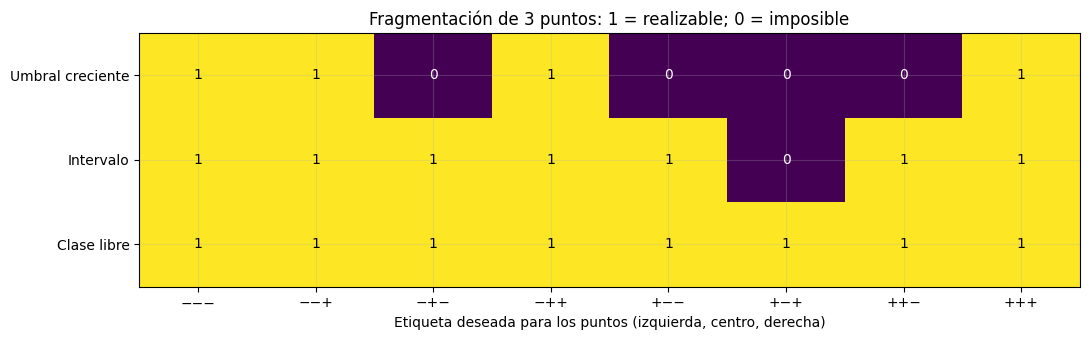

Conclusión demostrada: VC(umbrales crecientes) = 1; VC(intervalos) = 2.


In [ ]:
# Colocamos tres puntos concretos, de izquierda a derecha: -1, 0 y 1.
x_3 = np.array([-1., 0., 1.])
# Enumeramos los 2^3 = 8 etiquetados objetivo posibles con -1 y +1.
objetivos = np.asarray(list(itertools.product([-1, 1], repeat=3)))
# Creamos un diccionario que asocia cada familia con las predicciones que puede realizar.
modelos_patrones = {
    # Primera clase: reglas de umbral con el sentido -1 a +1.
    'Umbral creciente': predicciones_umbral(x_3),
    # Segunda clase: un bloque contiguo de positivos.
    'Intervalo': predicciones_intervalo(x_3),
    # Tercera clase: todas las etiquetas binarias admisibles.
    'Clase libre': predicciones_libres(x_3),
}
# Construimos una matriz de sí/no: filas = clases y columnas = etiquetas objetivo.
matriz = np.asarray([
    # Para cada objetivo buscamos alguna hipótesis que coincida exactamente; 1 = sí, 0 = no.
    [int(any(np.array_equal(patron, candidato) for candidato in H)) for patron in objetivos]
    # Repetimos la comprobación para cada una de las tres familias de funciones.
    for H in modelos_patrones.values()
])
# Preparamos el lienzo y sus ejes para mostrar la matriz.
fig, ax = plt.subplots(figsize=(11, 3.5))
# Pintamos la matriz: color distinto para 0 (imposible) y 1 (posible).
im = ax.imshow(matriz, aspect='auto', vmin=0, vmax=1, cmap='viridis')
# Escribimos cada combinación de tres signos bajo la columna correspondiente.
ax.set_xticks(range(len(objetivos)), [''.join('+' if v==1 else '−' for v in o) for o in objetivos])
# Etiquetamos las filas con los nombres de las clases de hipótesis.
ax.set_yticks(range(len(modelos_patrones)), list(modelos_patrones))
# Indicamos qué significan los ocho patrones del eje horizontal.
ax.set_xlabel('Etiqueta deseada para los puntos (izquierda, centro, derecha)')
# Damos un título para interpretar los valores de la matriz.
ax.set_title('Fragmentación de 3 puntos: 1 = realizable; 0 = imposible')
# Recorremos todas las filas de la matriz para colocar el número dentro de cada celda.
for i in range(matriz.shape[0]):
    # Recorremos las ocho columnas dentro de cada fila.
    for j in range(matriz.shape[1]):
        # Anotamos el 0/1 en el centro; ajustamos el color del texto para que se lea.
        ax.text(j, i, str(matriz[i,j]), ha='center', va='center',
                color='white' if matriz[i,j] < .5 else 'black')
# Acomodamos márgenes para evitar que se corten las etiquetas.
plt.tight_layout()
# Mostramos la visualización terminada.
plt.show()

# Verificamos que los umbrales sí pueden fragmentar un conjunto de un punto.
assert etiqueta_fragmentable(predicciones_umbral(np.arange(1)))
# Verificamos que los umbrales no pueden representar todos los patrones de dos puntos.
assert not etiqueta_fragmentable(predicciones_umbral(np.arange(2)))
# Verificamos que los intervalos sí pueden fragmentar dos puntos.
assert etiqueta_fragmentable(predicciones_intervalo(np.arange(2)))
# Verificamos que un solo intervalo no puede representar todos los patrones de tres puntos.
assert not etiqueta_fragmentable(predicciones_intervalo(np.arange(3)))
# La conclusión refleja dos pruebas de cota inferior y superior para la VC de cada clase.
print('Conclusión demostrada: VC(umbrales crecientes) = 1; VC(intervalos) = 2.')

### 1.1 bis · Ver las hipótesis como predicciones sobre puntos

La matriz anterior resume si cada clase puede producir un etiquetado. **Ahora vamos a dibujar los puntos reales y lo que predice cada clase.** En cada fila probamos el mismo objetivo para los puntos $x=-1,0,1$:

- **Círculo de borde negro:** etiqueta que queremos reproducir.
- **Punto verde:** predicción correcta del mejor modelo de esa clase.
- **Cruz roja:** predicción incorrecta; la línea punteada señala la etiqueta deseada.
- **Escalones azules:** regla de clasificación de un umbral o intervalo entre puntos (solo a modo de representante de las predicciones observadas).

Para cada clase elegimos una hipótesis que **minimiza el número de errores** en los tres puntos. Si el mínimo es cero, *ese patrón* es realizable. **Fragmentar los tres puntos es más exigente:** requiere error cero para **los ocho patrones**, no solo para estos dos ejemplos.

En el segundo ejemplo $(+1,-1,+1)$, ningún intervalo único puede acertar los tres puntos. La «clase libre» solo asigna etiquetas a los puntos observados: **no se presupone una curva entre ellos**.

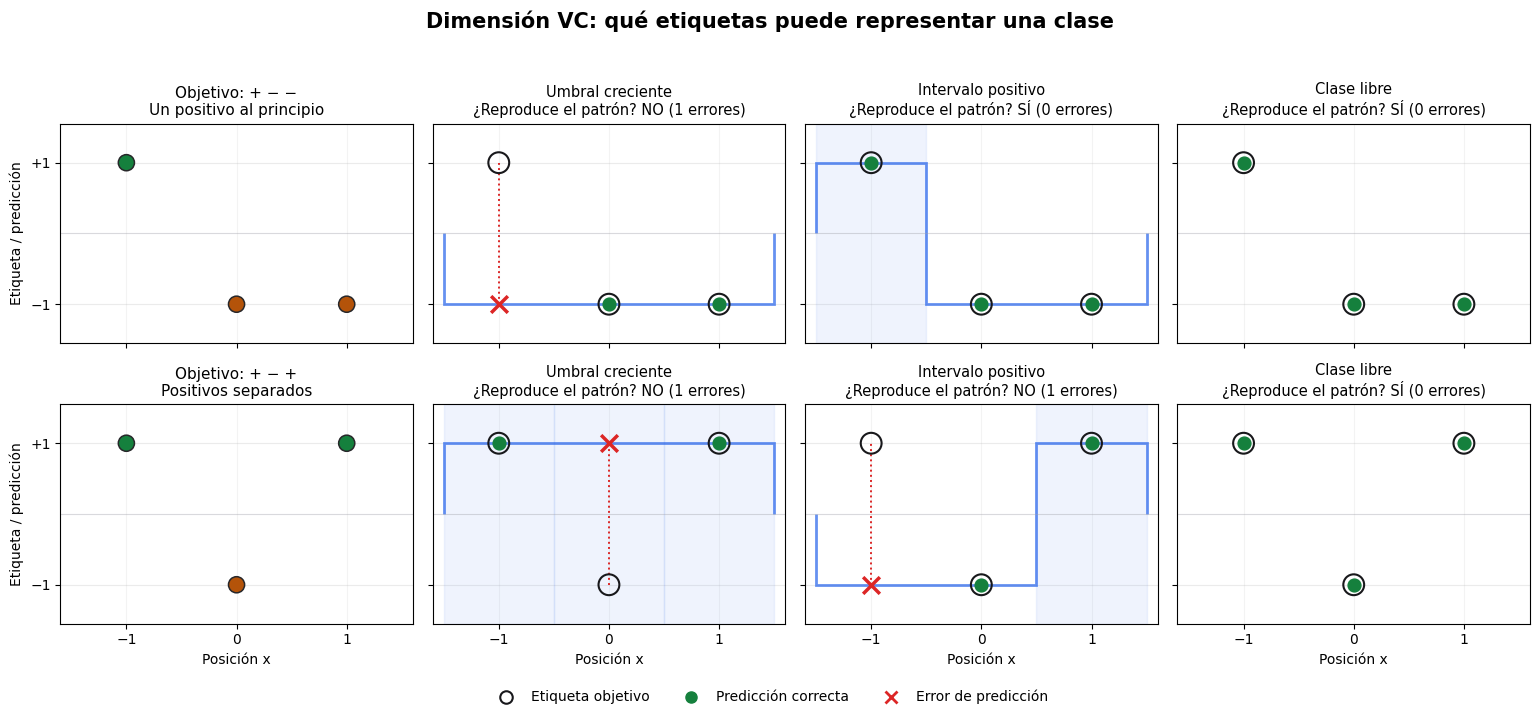

In [ ]:
# Esta figura compara, para cada familia de modelos, la etiqueta deseada con la mejor predicción posible.
# Figura explicativa: el objetivo frente al mejor etiquetado posible de cada clase.
# Puedes reemplazar las combinaciones de signos del ejemplo para explorar otros casos.
# Prueba a cambiar las dos tuplas de `casos` por cualquier secuencia de +1 y -1.
# Line2D permite crear símbolos personalizados para la leyenda de la figura.
from matplotlib.lines import Line2D


# Definimos una función reutilizable; casos controla los ejemplos y guardar es opcional.
def visualizar_patrones_vc(casos=None, guardar=None):
    # Si no se proporcionan patrones, usaremos dos casos ilustrativos.
    if casos is None:
        # Guardamos una lista de pares (descripción, secuencia de tres etiquetas).
        casos = [
            # Primer ejemplo: el positivo está a la izquierda; un umbral creciente no puede aislarlo.
            ('Un positivo al principio', (+1, -1, -1)),
            # Segundo ejemplo: dos positivos separados; un intervalo no puede producirlo.
            ('Positivos separados',     (+1, -1, +1)),
        ]
    # Fijamos los tres puntos de entrada para comparar todas las clases con los mismos datos.
    x = np.array([-1.0, 0.0, 1.0])
    # Definimos bordes entre puntos para dibujar correctamente las funciones escalonadas.
    bordes = np.array([-1.5, -0.5, 0.5, 1.5])
    # Agrupamos el nombre de cada familia y la función que genera sus hipótesis.
    clases = [
        # Los umbrales crecientes solo pueden pasar de -1 a +1 una vez.
        ('Umbral creciente', predicciones_umbral),
        # Los intervalos positivos necesitan un único bloque contiguo de +1.
        ('Intervalo positivo', predicciones_intervalo),
        # La clase libre puede asignar las etiquetas arbitrariamente a los tres puntos.
        ('Clase libre', predicciones_libres),
    ]
    # Creamos una fila por patrón y cuatro columnas: objetivo y tres clases; compartimos escalas.
    fig, axs = plt.subplots(len(casos), 4, figsize=(15.5, 3.5 * len(casos)),
                            # squeeze=False conserva una matriz de ejes incluso cuando solo existe una fila.
                            sharex=True, sharey=True, squeeze=False)

    # Recorremos cada patrón que queremos intentar reproducir.
    for fila, (descripcion, etiquetas) in enumerate(casos):
        # Convertimos las etiquetas de ese patrón a un vector entero.
        y = np.asarray(etiquetas, dtype=int)
        # Comprobamos que cada patrón tenga exactamente tres entradas y solo use -1 y +1.
        if y.shape != (3,) or not np.all(np.isin(y, [-1, +1])):
            # Interrumpimos con un mensaje claro cuando un ejemplo no cumple el formato esperado.
            raise ValueError('Cada ejemplo debe contener tres etiquetas +1/-1.')
        # Construimos una representación legible del patrón, por ejemplo + − +.
        texto_patron = ' '.join('+' if v == 1 else '−' for v in y)

        # Recorremos las cuatro gráficas de la fila actual.
        for columna, ax in enumerate(axs[fila]):
            # Fijamos el rango horizontal para comparar posiciones y regiones por igual.
            ax.set_xlim(-1.6, 1.6)
            # Fijamos el rango vertical para mostrar correctamente las dos etiquetas.
            ax.set_ylim(-1.55, 1.55)
            # Marcamos -1 y +1 en el eje vertical.
            ax.set_yticks([-1, 1], ['−1', '+1'])
            # Marcamos los tres valores de x en el eje horizontal.
            ax.set_xticks(x, ['−1', '0', '1'])
            # Dibujamos una línea horizontal tenue que separa las etiquetas positivas y negativas.
            ax.axhline(0, color='#a1a1aa', lw=0.8, alpha=0.4)
            # Añadimos guías verticales discretas para seguir la posición de cada dato.
            ax.grid(axis='x', alpha=0.15)
            # Colocamos la cuadrícula detrás de los puntos para no ocultarlos.
            ax.set_axisbelow(True)
            # Mostramos el nombre del eje x solamente en la última fila de gráficos.
            if fila == len(casos) - 1:
                # La etiqueta del eje horizontal será «Posición x».
                ax.set_xlabel('Posición x')
            # La primera columna contiene las etiquetas objetivo, no un modelo entrenado.
            if columna == 0:
                # Escribimos que el eje vertical representa etiquetas o predicciones.
                ax.set_ylabel('Etiqueta / predicción')
                # Mostramos como título la secuencia objetivo y la descripción del caso.
                ax.set_title(f'Objetivo: {texto_patron}\n{descripcion}', fontsize=11)
                # Dibujamos los tres puntos originales, con color según la etiqueta deseada.
                ax.scatter(x, y, s=135, c=np.where(y == 1, '#15803d', '#b45309'),
                           # Ajustamos el borde y la prioridad de dibujo de los puntos.
                           edgecolors='#27272a', linewidths=1.1, zorder=4)
                # Pasamos a la siguiente columna porque la primera ya quedó dibujada.
                continue

            # Seleccionamos la familia de hipótesis correspondiente a esta columna.
            nombre, generar_H = clases[columna - 1]
            # Generamos todas las predicciones que esa familia puede dar en nuestros tres puntos.
            H = generar_H(x)
            # Contamos errores respecto al objetivo, hipótesis por hipótesis.
            errores = np.count_nonzero(H != y, axis=1)
            # Registramos el mínimo número de errores alcanzable por esta familia.
            minimo = int(errores.min())
            # Elegimos una hipótesis que logre ese mínimo (si hay empate, la primera).
            h = H[int(np.argmin(errores))]
            # Comparamos la predicción elegida con el objetivo punto por punto.
            aciertos = h == y

            # Los escalones solo son una representación de las reglas de umbral e intervalo.
            # Los escalones son válidos para umbrales e intervalos;
            # Para la clase libre no suponemos ninguna regla sobre puntos no observados.
            # no hay una interpolación definida para la clase libre.
            # Dibujamos regiones solo para las clases con una interpretación intervalar.
            if columna < 3:
                # Recorremos cada tramo horizontal y la etiqueta que predice la hipótesis.
                for izq, der, etiqueta in zip(bordes[:-1], bordes[1:], h):
                    # Comprobamos si el tramo actual corresponde a una predicción positiva.
                    if etiqueta == +1:
                        # Sombreamos tenuemente las regiones predichas como clase +1.
                        ax.axvspan(izq, der, color='#2563eb', alpha=0.07)
                # Dibujamos una línea escalonada que representa cómo clasifica la hipótesis.
                ax.stairs(h, bordes, linewidth=2, color='#2563eb', alpha=0.7)

            # El círculo sin relleno representa el valor deseado, no necesariamente el predicho.
            # Cada círculo hueco es una etiqueta buscada. Las marcas son predicciones.
            # Mostramos de nuevo el objetivo para compararlo con los resultados.
            ax.scatter(x, y, s=225, marker='o', facecolors='none',
                       # Esta continuación da un contorno negro a los círculos objetivo.
                       edgecolors='#18181b', linewidths=1.5, zorder=5)
            # Pintamos en verde las posiciones en que el modelo acertó.
            ax.scatter(x[aciertos], h[aciertos], s=85, marker='o',
                       # Esta continuación define tamaño, color y prioridad de los aciertos.
                       color='#15803d', zorder=6)
            # Si el modelo cometió algún error, dibujamos marcas adicionales.
            if np.any(~aciertos):
                # Trazamos segmentos que conectan la etiqueta real y la etiqueta equivocada.
                ax.vlines(x[~aciertos], ymin=np.minimum(y[~aciertos], h[~aciertos]),
                          # Aquí fijamos el extremo superior de esos segmentos.
                          ymax=np.maximum(y[~aciertos], h[~aciertos]),
                          # Los segmentos de error serán rojos, punteados y delgados.
                          colors='#dc2626', linestyles=':', linewidth=1.4)
                # Situamos una cruz roja exactamente en la predicción equivocada.
                ax.scatter(x[~aciertos], h[~aciertos], s=145, marker='x',
                           # Ajustamos la apariencia de las cruces de error.
                           color='#dc2626', linewidths=2.5, zorder=7)
            # Si el número mínimo de errores es cero, el patrón es realizable por esa familia.
            estado = 'SÍ' if minimo == 0 else 'NO'
            # Escribimos el nombre de la familia, si reprodujo el patrón y el número de errores.
            ax.set_title(f'{nombre}\n¿Reproduce el patrón? {estado} ({minimo} errores)',
                         # Esta continuación ajusta el tamaño de letra del título.
                         fontsize=10.5)

    # Creamos una leyenda personalizada para descifrar símbolos y colores.
    leyenda = [
        # Primer símbolo: círculo transparente que marca una etiqueta objetivo.
        Line2D([0], [0], marker='o', color='none', markerfacecolor='none',
               # Esta continuación ajusta el borde de ese círculo.
               markeredgecolor='#18181b', markeredgewidth=1.5, markersize=9,
               # El primer texto de la leyenda indica «Etiqueta objetivo».
               label='Etiqueta objetivo'),
        # Segundo símbolo: círculo verde para una predicción que coincide.
        Line2D([0], [0], marker='o', color='none', markerfacecolor='#15803d',
               # Esta continuación ajusta su tamaño y su borde.
               markeredgecolor='#15803d', markersize=8,
               # El segundo texto de la leyenda indica «Predicción correcta».
               label='Predicción correcta'),
        # Tercer símbolo: cruz roja que señala un error de clasificación.
        Line2D([0], [0], marker='x', color='#dc2626', linestyle='none',
               # Esta continuación da estilo a la cruz y su descripción.
               markeredgewidth=2, markersize=9, label='Error de predicción'),
    ]
    # Ponemos la leyenda debajo de las gráficas, distribuida en tres columnas.
    fig.legend(handles=leyenda, loc='lower center', ncol=3,
               # La colocamos ligeramente por debajo de los ejes y sin recuadro.
               bbox_to_anchor=(0.5, 0.005), frameon=False)
    # Añadimos el título general de la figura.
    fig.suptitle('Dimensión VC: qué etiquetas puede representar una clase',
                 # Ajustamos el tamaño, el grosor de la letra y la posición de ese título.
                 fontsize=15, fontweight='bold', y=1.015)
    # Reservamos espacio para el título y la leyenda para que no se solapen.
    fig.tight_layout(rect=[0, 0.055, 1, 0.985])
    # Verificamos si se pidió guardar el gráfico en un archivo.
    if guardar is not None:
        # Si guardar contiene una ruta, exportamos la figura con buena resolución.
        fig.savefig(guardar, dpi=160, bbox_inches='tight')
    # Mostramos la figura en Colab.
    plt.show()


# Ejecutamos los dos casos de ejemplo predefinidos.
visualizar_patrones_vc()

# Ejemplo para explorar: visualizar_patrones_vc([('Alternancia', (-1, +1, -1))])

### 1.2 Función de crecimiento y dimensión VC

La **función de crecimiento** $m_{\mathscr H}(n)$ cuenta cuántos etiquetados distintos puede producir la clase **como máximo** sobre cualquier conjunto de $n$ entradas.

Para $n$ puntos distintos y ordenados en una recta:

$$
 m_{\rm umbral}(n)=n+1,\qquad
 m_{\rm intervalo}(n)=1+\frac{n(n+1)}2,\qquad
 m_{\rm libre}(n)=2^n.
$$

Los dos primeros crecen mucho más lentamente que $2^n$. Si una clase tiene dimensión VC finita $d$, el lema de Sauer–Shelah establece que $m_{\mathscr H}(n)\leq\sum_{k=0}^d {n\choose k}$ para $n\geq d$. **Esta restricción combinatoria abre la puerta a generalizar.**

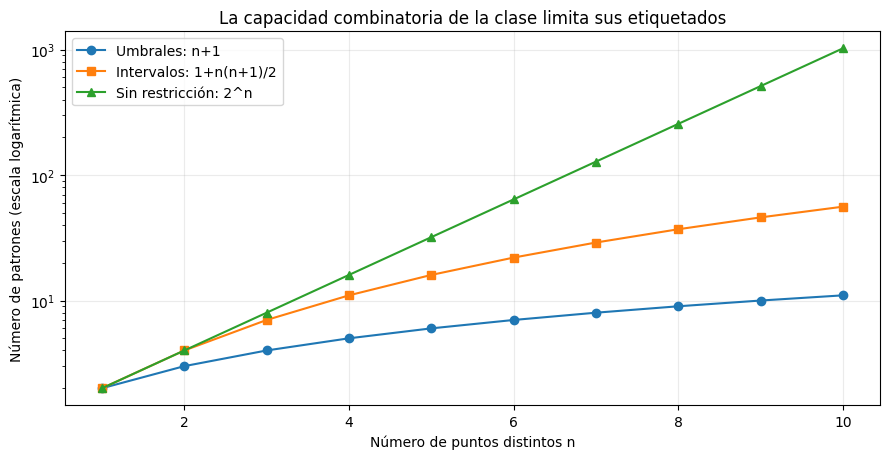

In [ ]:
# Variamos el número n de puntos distintos desde 1 hasta 10.
ns = np.arange(1, 11)
# Con n entradas distintas, los umbrales crecientes producen n+1 patrones.
plt.figure()
# Los intervalos positivos producen 1+n(n+1)/2 patrones.
plt.plot(ns, ns+1, 'o-', label='Umbrales: n+1')
# Una clase totalmente libre admite las 2^n asignaciones de etiquetas.
plt.plot(ns, 1+ns*(ns+1)/2, 's-', label='Intervalos: 1+n(n+1)/2')
# Usamos escala logarítmica porque 2^n crece mucho más rápido.
plt.plot(ns, 2**ns, '^-', label='Sin restricción: 2^n')
# Nombramos el tamaño del conjunto de entradas.
plt.yscale('log')
# Aclaramos que el eje vertical expresa cantidad de patrones en logaritmo.
plt.xlabel('Número de puntos distintos n')
# Damos un título que conecta cantidad de patrones con capacidad.
plt.ylabel('Número de patrones (escala logarítmica)')
# Identificamos las tres curvas; ajustamos el diseño y mostramos la figura.
plt.title('La capacidad combinatoria de la clase limita sus etiquetados')
plt.legend(); plt.tight_layout(); plt.show()

**Pregunta de comprobación.** ¿Una hipótesis de dimensión VC baja necesariamente predice mejor? **No.** La capacidad pequeña ayuda a controlar el sobreajuste, pero también puede producir **subajuste** si la estructura real no pertenece a la clase. Vamos a construir el contraejemplo.

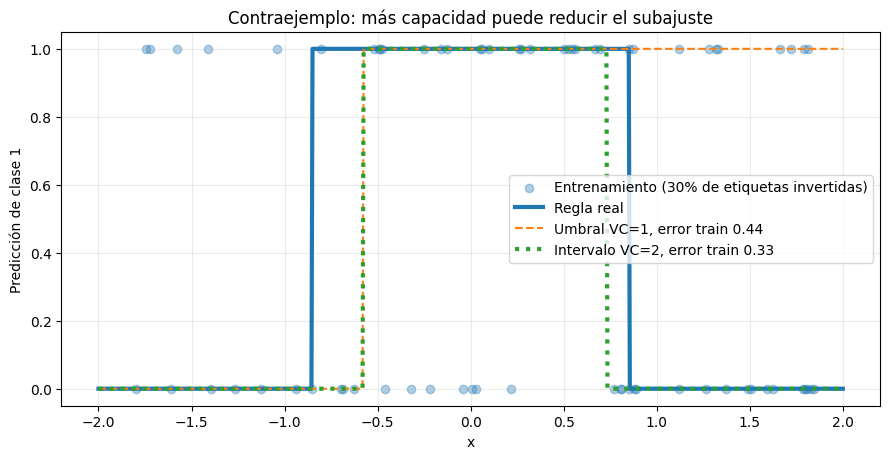

In [ ]:
# Buscamos el umbral que minimiza el error de clasificación en los datos (ERM).
def ajustar_umbral_creciente(x, y):
    # La salida será la frontera óptima y su proporción de errores.
    """ERM exacto en la clase: predecir 0 a la izquierda y 1 a la derecha."""
    # Ordenamos los índices de los datos de menor a mayor valor de x.
    orden = np.argsort(x)
    # Aplicamos ese orden tanto a las entradas como a sus etiquetas.
    xs, ys = np.asarray(x)[orden], np.asarray(y)[orden]
    # Guardamos cuántos ejemplos hay para probar todas las posiciones de corte.
    n = len(xs)
    # Contamos los positivos acumulados a la izquierda de cada posible corte.
    positivos_izq = np.r_[0, np.cumsum(ys)]
    # Restamos para saber cuántos negativos quedan a la izquierda de cada corte.
    negativos_izq = np.arange(n+1) - positivos_izq
    # Error del corte k = positivos mal clasificados a la izquierda + negativos a la derecha.
    errores = positivos_izq + ((n - np.sum(ys)) - negativos_izq)
    # Elegimos el corte k que produce el menor número de errores.
    k = int(np.argmin(errores))
    # Con corte antes del primer dato, todos se predicen como 1.
    if k == 0: t = -np.inf
    # Con corte después del último dato, todos se predicen como 0.
    elif k == n: t = np.inf
    # En los demás casos, la frontera queda a mitad entre dos entradas contiguas.
    else: t = (xs[k-1] + xs[k])/2
    # Devolvemos el corte óptimo y el error relativo dividido entre n.
    return t, errores[k] / n

# Ahora buscamos el mejor intervalo positivo bajo la misma pérdida de clasificación.
def ajustar_intervalo(x, y):
    # El método es exhaustivo: evalúa todos los intervalos distintos de la muestra.
    """ERM exhaustivo para intervalos de n puntos distintos."""
    # H contiene una fila de predicciones por cada intervalo que se puede formar.
    H = predicciones_intervalo(x)
    # Convertimos las etiquetas de entrenamiento 0/1 a -1/+1 para compararlas con H.
    objetivo = 2*np.asarray(y)-1
    # Calculamos qué fracción de datos clasifica mal cada intervalo.
    errores = np.mean(H != objetivo, axis=1)
    # Tomamos el patrón de predicciones que logra la menor tasa de error.
    mejor = H[np.argmin(errores)]
    # Ordenamos los datos originales para reconstruir los extremos del intervalo.
    orden = np.argsort(x)
    # Aplicamos el mismo orden a las entradas y al mejor patrón predicho.
    xs, hs = np.asarray(x)[orden], mejor[orden]
    # Buscamos dónde predice +1 la hipótesis elegida.
    indices = np.where(hs == 1)[0]
    # Comprobamos si el mejor patrón no contiene ningún positivo.
    if not len(indices):
        # Si el intervalo es vacío, regresamos extremos incompatibles y el error mínimo.
        return np.inf, -np.inf, np.min(errores)
    # Encontramos los índices del primero y último positivo del intervalo.
    a, b = indices[[0, -1]]
    # Calculamos el borde izquierdo, o -infinito si empieza en el primer punto.
    izq = -np.inf if a == 0 else (xs[a-1]+xs[a])/2
    # Calculamos el borde derecho, o +infinito si llega al último punto.
    der = np.inf if b == len(xs)-1 else (xs[b]+xs[b+1])/2
    # Devolvemos el intervalo óptimo y su tasa de error de entrenamiento.
    return izq, der, np.min(errores)

# Creamos un generador fijo para hacer reproducible este experimento.
rng_intervalo = np.random.default_rng(110)
# Generamos 70 entradas repartidas uniformemente entre -2 y 2.
x_i = rng_intervalo.uniform(-2, 2, 70)
# La regla verdadera asigna clase 1 a los puntos dentro de [-0.85, 0.85].
y_original = (np.abs(x_i) <= .85).astype(int)
# Invertimos aleatoriamente cerca del 7 % de las etiquetas para introducir ruido.       #MODIFICAR
y_i = np.where(rng_intervalo.random(len(x_i)) < .30, 1-y_original, y_original)
# Ajustamos el umbral creciente y almacenamos su error de entrenamiento.
t_i, e_u = ajustar_umbral_creciente(x_i, y_i)
# Ajustamos el intervalo positivo y almacenamos su error de entrenamiento.
a_i, b_i, e_i = ajustar_intervalo(x_i, y_i)
# Creamos una malla densa para representar las fronteras con una línea suave.
x_visual = np.linspace(-2, 2, 700)
# Abrimos una nueva figura.
plt.figure()
# Dibujamos como puntos los datos ruidosos usados para entrenar.
plt.scatter(x_i, y_i, alpha=.35, label='Entrenamiento (30% de etiquetas invertidas)')
# Dibujamos como línea la regla verdadera, antes de añadir ruido.
plt.plot(x_visual, (np.abs(x_visual) <= .85).astype(int), linewidth=3, label='Regla real')
# Dibujamos la predicción del umbral y mostramos su error sobre entrenamiento.
plt.plot(x_visual, (x_visual >= t_i).astype(int), '--', label=f'Umbral VC=1, error train {e_u:.2f}')
# Dibujamos la predicción del mejor intervalo, según sus dos fronteras.
plt.plot(x_visual, ((x_visual >= a_i)&(x_visual <= b_i)).astype(int), ':', linewidth=3,
         # La etiqueta de esa curva incluye su error y la dimensión VC de la clase.
         label=f'Intervalo VC=2, error train {e_i:.2f}')
# El título destaca que mayor flexibilidad a veces disminuye el subajuste.
plt.title('Contraejemplo: más capacidad puede reducir el subajuste')
# Etiquetamos entrada y salida de la clasificación.
plt.xlabel('x'); plt.ylabel('Predicción de clase 1')
# Añadimos leyenda, ajustamos los márgenes y mostramos la gráfica.
plt.legend(); plt.tight_layout(); plt.show()

## 2. Complejidad de Rademacher: ¿qué tan bien podemos ajustar etiquetas aleatorias?

**Experimento mental:** ignoramos las etiquetas reales y lanzamos una moneda por cada observación. Los signos $\sigma_i\in\{-1,+1\}$ son independientes y equiprobables. Pedimos al modelo más favorecido por esas monedas que se alinee con ellas.

Para funciones binarias $h(x)\in\{-1,+1\}$, la complejidad **empírica** sobre las entradas $S_X=(x_1,\ldots,x_n)$ es:

$$
\widehat{\mathfrak R}_{S_X}(\mathscr H)
=\mathbb E_\sigma\!\left[\sup_{h\in\mathscr H}
\frac1n\sum_{i=1}^n\sigma_i h(x_i)\right].
$$

- Los signos $\sigma_i$ representan **ruido aleatorio**, no las etiquetas verdaderas.
- El supremo elige *el mejor modelo de toda la clase para esos signos*.
- La esperanza repite el experimento para todos los lanzamientos posibles.
- Valor cerca de **1**: la clase puede memorizar etiquetas aleatorias en estos puntos. Valor bajo: menor capacidad de ajustarse al ruido.

En particular, si la clase realiza todas las $2^n$ asignaciones sobre los $n$ puntos observados, elegir $h(x_i)=\sigma_i$ produce complejidad 1.

In [ ]:
# Calculamos la complejidad de Rademacher de una clase finita representada por H.
def rademacher_exacto(H):
    # El método exacto requiere enumerar todos los vectores de signos y solo sirve para n pequeño.
    """Enumera los 2**n vectores de signos: útil solo para n pequeño."""
    # Convertimos H a una matriz numérica: filas = hipótesis; columnas = observaciones.
    H = np.asarray(H, dtype=float)
    # n es el número de observaciones sobre las que se calcula la complejidad.
    n = H.shape[1]
    # Evitamos la enumeración exponencial si el número de puntos resulta demasiado alto.
    if n > 12:
        # Sugerimos Monte Carlo para los casos que exceden el tamaño permitido.
        raise ValueError('Usa Monte Carlo para más de 12 puntos.')
    # Enumeramos los 2^n vectores sigma con signos independientes equiprobables.
    sigmas = np.asarray(list(itertools.product([-1, 1], repeat=n)), dtype=float)
    # Para cada sigma, calculamos el producto promedio con cada h y conservamos el máximo.
    mejores_puntajes = np.max(sigmas @ H.T, axis=1) / n
    # Promediamos los mejores valores de todas las realizaciones de sigma.
    return float(np.mean(mejores_puntajes))

# Elegimos ocho entradas diferentes para el ejemplo.
x_r = np.arange(8)
# Preparamos una tabla con una fila por familia de hipótesis.
resultados_r = pd.DataFrame([
    # Guardamos nombre y número de patrones diferentes presentes sobre los ocho puntos.
    {'Clase': nombre, 'Patrones sobre la muestra': len(H),
     # Calculamos exactamente la complejidad de Rademacher de esa familia.
     'Rademacher exacta': rademacher_exacto(H)}
    # Primera familia: umbrales.
    for nombre, H in [('Umbrales', predicciones_umbral(x_r)),
                       # Segunda familia: intervalos positivos.
                       ('Intervalos', predicciones_intervalo(x_r)),
                       # Tercera familia: todas las asignaciones de etiquetas.
                       ('Funciones libres', predicciones_libres(x_r))]
])
# Mostramos la tabla obtenida.
display(resultados_r)
# Comprobamos que la clase libre logra Rademacher = 1 al poder imitar cualquier sigma.
assert np.isclose(resultados_r.loc[2, 'Rademacher exacta'], 1.)
# Esta interpretación expresa la capacidad máxima de ajustar ruido de signos.
print('Interpretación: sobre ocho puntos, la clase libre memoriza cualquier ruido.')

,Clase,Patrones sobre la muestra,Rademacher exacta
0,Umbrales,9,0.4561
1,Intervalos,37,0.6680
2,Funciones libres,256,1.0000


Interpretación: sobre ocho puntos, la clase libre memoriza cualquier ruido.


### 2.1 La muestra también importa

A diferencia de VC, $\widehat{\mathfrak R}_{S_X}$ **depende de las entradas concretas**. Una función no puede asignar dos valores distintos a una misma entrada repetida. Comparemos ocho entradas diferentes con ocho observaciones que repiten solo dos posiciones.

,Clase,8 valores distintos,Solo 2 valores distintos
0,Umbral,0.4561,0.3652
1,Intervalo,0.6680,0.4746
2,Funciones libres,1.0000,0.5000


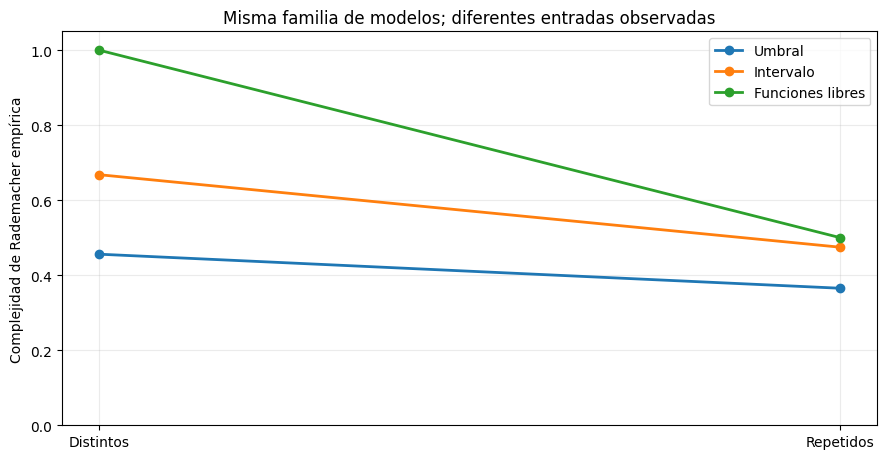

In [ ]:
# Primera muestra: ocho valores de entrada diferentes.
x_distintos = np.arange(8)
# Segunda muestra: ocho observaciones, pero solo dos valores distintos repetidos.
x_repetidos = np.repeat([0., 1., .2, .3], 2)
# Preparamos una lista donde registrar las complejidades de ambas muestras.
rows=[]
# Repetimos el experimento para tres familias fijas de hipótesis.
for nombre, fn in [('Umbral', predicciones_umbral),
                   # Incluimos la clase de intervalos.
                   ('Intervalo', predicciones_intervalo),
                   # Incluimos la clase libre definida como funciones de las entradas x.
                   ('Funciones libres', predicciones_libres)]:
    # Calculamos la Rademacher exacta sobre ocho x distintos.
    rows.append((nombre, rademacher_exacto(fn(x_distintos)),
                 # Calculamos la Rademacher exacta sobre ocho observaciones repetidas.
                 rademacher_exacto(fn(x_repetidos))))
# Convertimos las comparaciones en una tabla con columnas descriptivas.
res = pd.DataFrame(rows, columns=['Clase', '8 valores distintos', 'Solo 2 valores distintos'])
# Presentamos los valores numéricos obtenidos.
display(res)
# Abrimos la gráfica de comparación.
plt.figure()
# Recorremos las filas de la tabla, una por clase.
for _, fila in res.iterrows():
    # Colocamos los dos tipos de muestra en el eje horizontal.
    plt.plot(['Distintos', 'Repetidos'],
             # Obtenemos las dos complejidades que corresponden a esa clase.
             [fila['8 valores distintos'], fila['Solo 2 valores distintos']],
             # Dibujamos una línea que conecta ambas para apreciar la diferencia.
             'o-', linewidth=2, label=fila['Clase'])
# Fijamos el eje vertical en el rango admisible 0 a 1 (con margen).
plt.ylim(0, 1.05)
# Indicamos qué se mide en el eje vertical.
plt.ylabel('Complejidad de Rademacher empírica')
# Enfatizamos que cambió la muestra, no la definición de la clase.
plt.title('Misma familia de modelos; diferentes entradas observadas')
# Añadimos leyenda, ajustamos el diseño y mostramos la gráfica.
plt.legend(); plt.tight_layout(); plt.show()

### 2.2 Rademacher disminuye con más datos si la clase no es demasiado rica

En una clase finita de vectores de predicciones binarias observados, una cota útil es la **cota de Massart**:

$$
\widehat{\mathfrak R}_{S_X}(\mathscr H)\leq
\sqrt{\frac{2\log |\mathscr H(S_X)|}{n}},
$$

donde $\mathscr H(S_X)$ son los patrones distintos que la clase produce sobre las entradas. La cota puede ser poco informativa si supera 1; no es una igualdad. Esta fórmula hace intuitiva la conexión: **pocos patrones** implican menos capacidad para correlacionarse con signos aleatorios.

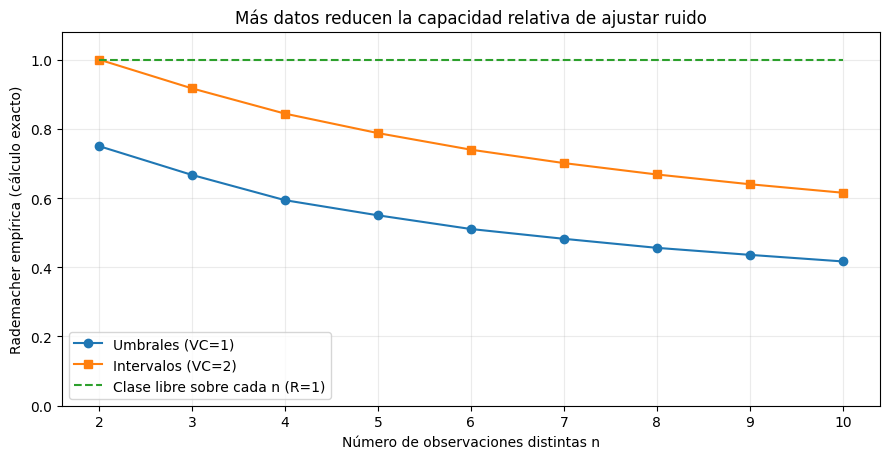

In [ ]:
# Analizamos muestras de 2 a 10 observaciones distintas.
valores_n = np.arange(2, 11)
# Calculamos la complejidad de los umbrales para cada tamaño n.
R_umbral = [rademacher_exacto(predicciones_umbral(np.arange(n))) for n in valores_n]
# Calculamos la complejidad de los intervalos para cada tamaño n.
R_intervalo = [rademacher_exacto(predicciones_intervalo(np.arange(n))) for n in valores_n]
# Iniciamos la gráfica que mostrará cómo varía la complejidad con n.
plt.figure()
# Dibujamos la complejidad exacta de umbrales (VC = 1).
plt.plot(valores_n, R_umbral, 'o-', label='Umbrales (VC=1)')
# Dibujamos la complejidad exacta de intervalos (VC = 2).
plt.plot(valores_n, R_intervalo, 's-', label='Intervalos (VC=2)')
# Dibujamos la referencia de una clase totalmente libre: complejidad 1 siempre.
plt.plot(valores_n, np.ones(len(valores_n)), '--', label='Clase libre sobre cada n (R=1)')
# Nombramos el tamaño de la muestra usado en cada cálculo.
plt.xlabel('Número de observaciones distintas n')
# Aclaramos qué muestra el eje vertical y que el cálculo es exacto.
plt.ylabel('Rademacher empírica (cálculo exacto)')
# El título resume la caída relativa de capacidad para ajustar signos aleatorios.
plt.title('Más datos reducen la capacidad relativa de ajustar ruido')
# Limitamos el eje vertical, mostramos leyenda y desplegamos la gráfica.
plt.ylim(0, 1.08); plt.legend(); plt.tight_layout(); plt.show()

**Conexión formal VC–Rademacher.** La dimensión VC controla el número máximo de patrones (Sauer–Shelah); ese número controla la complejidad de Rademacher (Massart). Para clases binarias con VC $d$ finita, surgen cotas de orden $O(\sqrt{d\log(n/d)/n})$ para $n$ mayor que $d$; hay resultados más finos de orden $O(\sqrt{d/n})$ bajo hipótesis habituales. Las constantes dependen del teorema. **VC es capacidad combinatoria de una clase; Rademacher es correlación media con ruido sobre una muestra.**

## 3. Algoritmos predictivos: capacidad, sesgo, varianza y sobreajuste

Generaremos datos con relación **no lineal**:

$$
X\sim U[-3,3],\quad
P(Y=1\mid X=x)=\operatorname{sigmoid}(1.8\sin(2.4x)+0.35x).
$$

Aunque conozcamos $x$, $Y$ sigue siendo aleatorio (ruido irreducible). Compararemos un árbol poco profundo con otros más expresivos; estos algoritmos pueden ajustar fronteras irregulares, pero el último tiende a memorizar ruido.

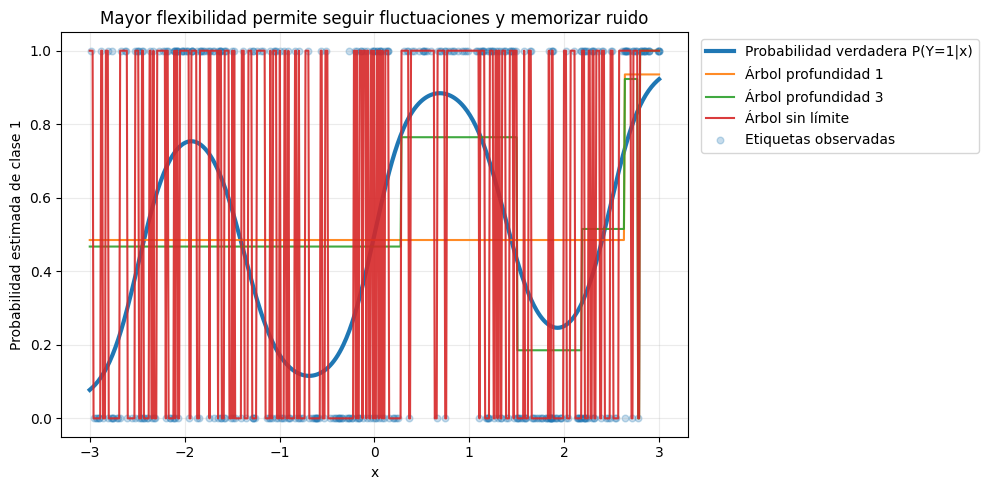

In [ ]:
# Esta función define la probabilidad verdadera de clase 1 para cada valor x.
def prob_real(x):
    # La sigmoide de una curva no lineal crea probabilidades entre 0 y 1.
    return expit(1.8*np.sin(2.4*np.asarray(x)) + .35*np.asarray(x))

# Esta función simula ejemplos de clasificación usando una distribución conocida.
def generar_datos(n, generador):
    # Elegimos n entradas x uniformes entre -3 y 3.
    x = generador.uniform(-3, 3, n)
    # Para cada x, sorteamos una etiqueta Bernoulli usando su probabilidad verdadera.
    y = generador.binomial(1, prob_real(x))
    # Devolvemos tanto las características como las etiquetas observadas.
    return x, y

# Generamos una muestra pequeña de entrenamiento: 72 casos.
x_train, y_train = generar_datos(400, np.random.default_rng(210)) #MODIFICADO
# Generamos una muestra de prueba grande e independiente: 10 000 casos.
x_test, y_test = generar_datos(10000, np.random.default_rng(211))
# Creamos 600 valores de x para dibujar curvas de probabilidad.
x_plot = np.linspace(-3, 3, 600)
# Definimos tres árboles con distintos niveles de flexibilidad.
modelos = {
    # Un árbol de profundidad 1 solo puede hacer una partición.
    'Árbol profundidad 1': DecisionTreeClassifier(max_depth=1, random_state=4),
    # Un árbol de profundidad 3 puede realizar reglas algo más complejas.
    'Árbol profundidad 3': DecisionTreeClassifier(max_depth=3, random_state=4),
    # Sin límite de profundidad, el árbol puede memorizar muchos detalles y ruido.
    'Árbol sin límite': DecisionTreeClassifier(random_state=4),
}
# Recorremos los tres clasificadores para entrenarlos.
for mod in modelos.values():
    # Ajustamos cada árbol usando una sola variable de entrada y las etiquetas 0/1.
    mod.fit(x_train.reshape(-1,1), y_train)

# Creamos una figura ancha para comparar probabilidades.
plt.figure(figsize=(10, 5))
# Dibujamos la probabilidad real, que normalmente no conoceríamos en datos reales.
plt.plot(x_plot, prob_real(x_plot), linewidth=3, label='Probabilidad verdadera P(Y=1|x)')
# Recorremos los modelos entrenados para comparar sus curvas.
for nombre, mod in modelos.items():
    # Dibujamos la probabilidad de clase 1 estimada por cada modelo.
    plt.plot(x_plot, mod.predict_proba(x_plot.reshape(-1,1))[:,1], label=nombre, alpha=.9)
# Superponemos los ejemplos de entrenamiento; la transparencia evita saturación.
plt.scatter(x_train, y_train, alpha=.25, s=23, label='Etiquetas observadas')
# Nombramos ejes de entrada y probabilidad estimada.
plt.xlabel('x'); plt.ylabel('Probabilidad estimada de clase 1')
# El título señala cómo modelos flexibles pueden seguir fluctuaciones aleatorias.
plt.title('Mayor flexibilidad permite seguir fluctuaciones y memorizar ruido')
# Ponemos la leyenda fuera de la figura para no tapar las curvas.
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

In [ ]:
# Calculamos métricas de error para un modelo y un conjunto de datos dados.
def metricas_modelo(modelo, x, y):
    # Obtenemos p = P(Y=1|x) de predict_proba; reshape crea una columna de características.
    p = modelo.predict_proba(np.asarray(x).reshape(-1,1))[:,1]
    # Agrupamos las tres métricas en un diccionario con nombres legibles.
    return {
        # Error 0–1: proporción de clases equivocadas usando el umbral p >= 0.5.
        'Error 0-1': np.mean((p >= .5) != y),
        # Brier: promedio de (p-y)^2; castiga la distancia entre probabilidad y etiqueta.
        'Brier': brier_score_loss(y, p),
        # Log-loss: penalización logarítmica; recortamos p para evitar log(0).
        'Log-loss': log_loss(y, np.clip(p, 1e-8, 1-1e-8)),
    }

# Preparamos una lista para los resultados de todos los modelos.
filas=[]
# Evaluamos cada árbol de decisión guardado anteriormente.
for nombre, modelo in modelos.items():
    # Calculamos sus pérdidas sobre los ejemplos con los que entrenó.
    train = metricas_modelo(modelo, x_train, y_train)
    # Calculamos las mismas pérdidas sobre la muestra independiente de prueba.
    test = metricas_modelo(modelo, x_test, y_test)
    # Creamos una fila con nombre, métricas de entrenamiento y métricas de prueba.
    filas.append({'Modelo': nombre, **{f'{k} entrenamiento':v for k,v in train.items()},
                  # Los nombres de columnas distinguen el conjunto de entrenamiento del de prueba.
                  **{f'{k} prueba':v for k,v in test.items()}})
# Mostramos la tabla final para identificar posibles brechas de generalización.
display(pd.DataFrame(filas))

,Modelo,Error 0-1 entrenamiento,Brier entrenamiento,Log-loss entrenamiento,Error 0-1 prueba,Brier prueba,Log-loss prueba
0,Árbol profundidad 1,0.3611,0.2293,6.5095e-01,0.4054,0.2433,0.6801
1,Árbol profundidad 3,0.1806,0.1355,4.2117e-01,0.2969,0.2288,1.1016
2,Árbol sin límite,0.0000,0.0000,1.0000e-08,0.3524,0.3524,6.4914


### 3.1 Curvas de aprendizaje al aumentar la profundidad

Para un solo conjunto de entrenamiento y un conjunto grande de prueba, medimos la **pérdida de Brier** (error cuadrático de la probabilidad). Lo que importa es la distancia entre entrenamiento y prueba, no solo un entrenamiento cercano a cero. Un resultado particular puede variar con la semilla.

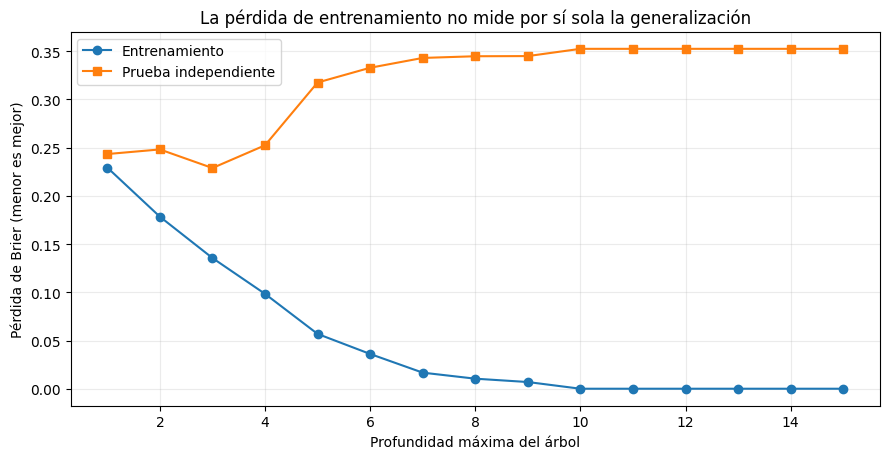

In [ ]:
# Probamos profundidades de árbol desde 1 hasta 15.
profundidades = np.arange(1, 16)
# Preparamos dos listas para almacenar los errores Brier de entrenamiento y prueba.
brier_train, brier_test = [], []
# Repetimos el ajuste para cada profundidad de árbol.
for profundidad in profundidades:
    # Construimos un árbol nuevo que solo cambia su máximo de profundidad.
    m = DecisionTreeClassifier(max_depth=int(profundidad), random_state=4)
    # Entrenamos el árbol con la misma muestra de 72 casos.
    m.fit(x_train.reshape(-1,1), y_train)
    # Guardamos su pérdida Brier en los datos de entrenamiento.
    brier_train.append(metricas_modelo(m, x_train, y_train)['Brier'])
    # Guardamos su pérdida Brier en los datos independientes de prueba.
    brier_test.append(metricas_modelo(m, x_test, y_test)['Brier'])
# Creamos la gráfica para comparar ambos errores.
plt.figure()
# Dibujamos error de entrenamiento según la capacidad del árbol.
plt.plot(profundidades, brier_train, 'o-', label='Entrenamiento')
# Dibujamos error de prueba para observar si aparece sobreajuste.
plt.plot(profundidades, brier_test, 's-', label='Prueba independiente')
# El eje horizontal es la profundidad máxima permitida.
plt.xlabel('Profundidad máxima del árbol')
# El eje vertical es pérdida Brier: valores más pequeños indican mejor ajuste.
plt.ylabel('Pérdida de Brier (menor es mejor)')
# El título recuerda que minimizar pérdida de entrenamiento no garantiza generalizar.
plt.title('La pérdida de entrenamiento no mide por sí sola la generalización')
# Mostramos leyenda y gráfica final.
plt.legend(); plt.tight_layout(); plt.show()

**Cuidado con tres afirmaciones erróneas:**

1. «Mayor dimensión VC siempre empeora un predictor». Falso: una clase demasiado pequeña puede subajustar (sección 1.2).
2. «Si el error de entrenamiento es 0, el modelo ya aprendió». Falso: puede memorizar ruido.
3. «La profundidad de un árbol es literalmente su dimensión VC». Falso: está relacionada con la expresividad, pero la dimensión VC exacta depende de la familia, características y restricciones; no estamos calculándola aquí.

## 4. Las funciones de pérdida conectan predicciones con generalización

La función $h$ produce predicciones. Una **pérdida** $\ell(h(x),y)$ penaliza su desacierto. El **riesgo poblacional** y el **riesgo empírico** son:

$$
R_\ell(h)=\mathbb E_{(X,Y)}[\ell(h(X),Y)],\qquad
\widehat R_{S,\ell}(h)=\frac1n\sum_{i=1}^n\ell(h(x_i),y_i).
$$

En clasificación probabilística, para etiqueta $y=1$ y probabilidad predicha $p$:

- **Error 0–1**: $\mathbb 1\{p<0.5\}$ (con convención de desempate en $0.5$).
- **Brier**: $(1-p)^2$, entre 0 y 1.
- **Log-loss**: $-\log p$, crece mucho ante errores confiados y **no está acotada** si $p\to0$.

Importa qué pérdida generalizamos: controlar el error 0–1 no garantiza que las probabilidades estén calibradas ni que su log-loss sea buena.

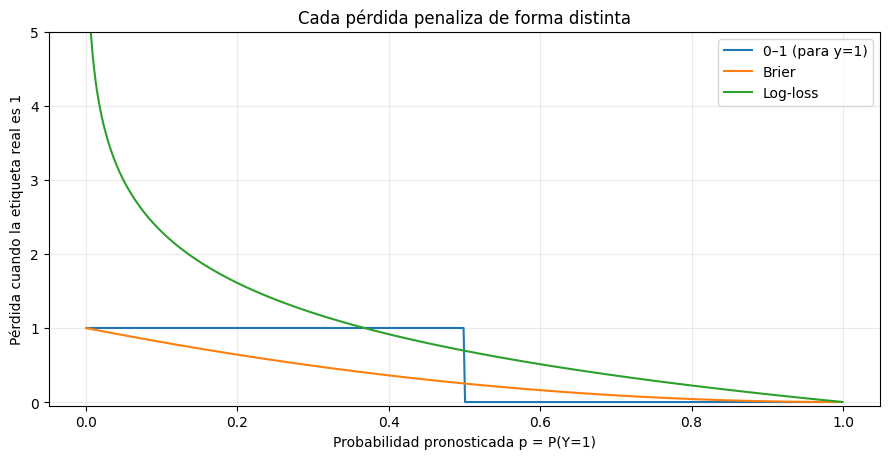

In [ ]:
# Generamos 500 probabilidades p cercanas, pero no iguales, a 0 y 1.
p_grid = np.linspace(.001, .999, 500)
# Abrimos la figura donde compararemos tres funciones de pérdida.
plt.figure()
# Para una etiqueta real y=1, el error 0–1 vale 1 si p < 0.5 y 0 en otro caso.
plt.plot(p_grid, (p_grid < .5).astype(float), label='0–1 (para y=1)')
# La pérdida Brier con y=1 es (1-p)^2.
plt.plot(p_grid, (1-p_grid)**2, label='Brier')
# La log-loss con y=1 es -log(p) y crece mucho cuando p se acerca a cero.
plt.plot(p_grid, -np.log(p_grid), label='Log-loss')
# Recortamos la escala visual para apreciar las tres curvas.
plt.ylim(-.05, 5)
# El eje x representa la probabilidad asignada a la clase verdadera.
plt.xlabel('Probabilidad pronosticada p = P(Y=1)')
# El eje y muestra la penalización de cada función cuando y=1.
plt.ylabel('Pérdida cuando la etiqueta real es 1')
# Destacamos que las pérdidas castigan de manera diferente las predicciones.
plt.title('Cada pérdida penaliza de forma distinta')
# Añadimos leyenda y mostramos la visualización.
plt.legend(); plt.tight_layout(); plt.show()

### 4.1 Rademacher de **la clase de pérdidas** (no solo de las predicciones)

Una cota del riesgo involucra $\ell\circ\mathscr H=\{(x,y)\mapsto\ell(h(x),y):h\in\mathscr H\}$. Para predicciones binarias $h,y\in\{-1,+1\}$ y pérdida 0–1:

$$
\ell_{0-1}(h(x),y)=\frac{1-yh(x)}{2}.
$$

Por simetría de los signos aleatorios, **para toda muestra etiquetada fija**:

$$
\boxed{\widehat{\mathfrak R}_{S}(\ell_{0-1}\circ\mathscr H)
=\tfrac12\,\widehat{\mathfrak R}_{S_X}(\mathscr H).}
$$

El factor $1/2$ es una identidad **especial de la pérdida 0–1 binaria con codificación $\pm1$**, no una regla universal para cualquier pérdida. Verifiquémosla por enumeración exacta.

In [ ]:
# Elegimos ocho entradas distintas para trabajar con una matriz pequeña.
x_loss = np.arange(8)
# Fijamos etiquetas reales en {-1,+1} para cada una de las ocho entradas.
y_loss = np.array([+1, -1, -1, +1, +1, -1, +1, -1])
# Obtenemos todas las predicciones de los intervalos posibles en esos puntos.
H_loss = predicciones_intervalo(x_loss)
# Construimos la clase de pérdidas 0–1: 1 si la predicción falla, 0 si acierta.
L_loss = (H_loss != y_loss).astype(float)  # filas = pérdidas de cada hipótesis
# Calculamos Rademacher sobre las predicciones con valores -1/+1.
rad_predicciones = rademacher_exacto(H_loss)
# Calculamos Rademacher sobre las pérdidas con valores 0/1.
rad_perdidas = rademacher_exacto(L_loss)
# Imprimimos la complejidad de la clase de predicciones.
print(f'Rad de las predicciones: {rad_predicciones:.6f}')
# Imprimimos la complejidad de la clase de pérdidas.
print(f'Rad de las pérdidas 0-1: {rad_perdidas:.6f}')
# Imprimimos la mitad de la primera complejidad para compararlas.
print(f'Mitad de la Rad de predicciones: {rad_predicciones/2:.6f}')
# Verificamos la identidad exacta Rad(pérdidas 0–1) = Rad(predicciones)/2.
assert np.isclose(rad_perdidas, rad_predicciones/2)
# Confirmamos que el resultado numérico coincide con la demostración.
print('Identidad matemática confirmada con enumeración exacta.')

Rad de las predicciones: 0.667969
Rad de las pérdidas 0-1: 0.333984
Mitad de la Rad de predicciones: 0.333984
Identidad matemática confirmada con enumeración exacta.


### 4.2 ¿Qué cambia si uso otra pérdida?

Para pérdidas **$L$-Lipschitz** respecto al valor real de predicción, los resultados de **contracción de Rademacher** permiten controlar la complejidad de la clase de pérdidas a partir de la de funciones de puntuación; los detalles exigen especificar el rango y la definición de complejidad. Para **log-loss**, una aplicación directa de cotas para pérdidas en $[0,1]$ es inválida sin acotar/normalizar la pérdida (por ejemplo, limitando las probabilidades lejos de 0 y de 1 y ajustando las constantes).

En regresión con pérdida cuadrática, hay un problema análogo: sin restricciones sobre el rango de $h$ y de $Y$, la pérdida puede no estar acotada. En clasificación con puntajes reales la dimensión VC de umbrales ya no describe por sí sola toda la riqueza de la pérdida; aparecen nociones como **pseudodimensión** y clases de subgráficas.

## 5. De Rademacher a la incertidumbre de generalización

Una forma estándar de la cota **uniforme**, para pérdidas en $[0,1]$, con probabilidad al menos $1-\delta$ sobre la muestra i.i.d., establece simultáneamente para todos los $h\in\mathscr H$:

$$
\boxed{ R_\ell(h)\ \leq\ \widehat R_{S,\ell}(h)
+ 2\widehat{\mathfrak R}_{S}(\ell\circ\mathscr H)
+3\sqrt{\frac{\log(2/\delta)}{2n}}.}
$$

El término de complejidad paga por seleccionar un predictor dentro de una familia flexible, y el último término captura la fluctuación muestral. Es una **garantía de error esperado**, no un «intervalo de confianza de 95%» para la etiqueta de cada persona.

**Práctica controlada.** Volvemos al modelo de umbrales crecientes, ahora en un problema donde la probabilidad real sí es monótona: $P(Y=1\mid X=x)=\sigma(1.7x)$ con $X\sim U[-2.5,2.5]$. Encontramos exactamente el umbral que minimiza el error de entrenamiento (ERM), y comparamos su riesgo verdadero (integración numérica) con la cota.

**Nota numérica:** la complejidad de Rademacher de cada muestra se aproximará mediante Monte Carlo, por lo que el valor calculado y la línea dibujada **ilustran** la cota teórica; esta aproximación por sí sola no certifica su nivel de confianza.

In [ ]:
# Estimamos Rademacher para umbrales mediante simulación, sin enumerar todos los signos.
def rad_umbral_montecarlo(n, repeticiones=3500, semilla=0):
    # La cadena explica el objetivo del método y su limitación.
    """Rademacher para umbrales sobre n x distintos, sin enumerar 2**n signos.

    # Suponemos los n puntos diferentes y ordenados; k define el corte del umbral.
    Si los primeros k puntos predicen -1 y los demás +1:
    # La suma de alineaciones se calcula con una suma total menos dos veces un prefijo.
    suma sigma_i h_i = suma sigma_i - 2*suma_{i<=k} sigma_i.
    """
    # Creamos el generador pseudoaleatorio para que Monte Carlo sea reproducible.
    rg = np.random.default_rng(semilla)
    # Simulamos repeticiones vectores de n signos independientes -1 o +1.
    signos = rg.choice([-1, 1], size=(repeticiones, n))
    # Calculamos las sumas acumuladas y agregamos el prefijo vacío, que vale cero.
    prefijos = np.c_[np.zeros(repeticiones), np.cumsum(signos, axis=1)]
    # Evaluamos la correlación con cada umbral y conservamos sus valores por simulación.
    valores = signos.sum(axis=1, keepdims=True) - 2*prefijos
    # Promediamos el mejor puntaje normalizado; es una estimación Monte Carlo, no exacta.
    return np.mean(valores.max(axis=1) / n)

# Definimos una probabilidad positiva que crece de manera monótona con x.
def prob_monotona(x):
    # La sigmoide garantiza que el resultado esté entre 0 y 1.
    return expit(1.7*np.asarray(x))

# Generamos una muestra donde un umbral tiene sentido como clasificador.
def generar_monotono(n, generador):
    # Sorteamos n entradas en el intervalo [-2.5,2.5].
    x = generador.uniform(-2.5, 2.5, n)
    # Sorteamos etiquetas Bernoulli según la probabilidad positiva en cada punto.
    y = generador.binomial(1, prob_monotona(x))
    # Devolvemos las entradas y sus etiquetas 0/1.
    return x, y

# Queremos comparar entrenamiento con el riesgo verdadero de la población.
# Integración de la probabilidad de equivocarse bajo la distribución verdadera.
# Creamos una malla muy densa como aproximación numérica a una integral.
_x_poblacional = np.linspace(-2.5, 2.5, 30001)
# Calculamos P(Y=1|x) en toda esa malla.
_p_poblacional = prob_monotona(_x_poblacional)
# Definimos el riesgo esperado de equivocarse para un umbral dado.
def riesgo_verdadero_umbral(t):
    # A la izquierda el umbral predice 0, así que falla con probabilidad p(x); a la derecha predice 1 y falla con 1-p(x).
    perdida = np.where(_x_poblacional < t, _p_poblacional, 1-_p_poblacional)
    # Promediamos el error condicional sobre x, aproximando la esperanza poblacional.
    return float(np.mean(perdida))

# Elegimos distintos tamaños de entrenamiento para estudiar la generalización.
N_EJEMPLOS = [40, 120, 400, 1200]
# Usamos delta=0.05 como parámetro teórico del nivel de confianza 1-delta.
DELTA = 0.01   #MODIFICADO
# Preparamos una lista para registrar resultados de cada tamaño muestral.
resultados_cota=[]
# Repetimos el experimento para cada tamaño de entrenamiento.
for n in N_EJEMPLOS:
    # Creamos una muestra independiente y reproducible de n observaciones.
    x_n, y_n = generar_monotono(n, np.random.default_rng(800+n))
    # Ajustamos el umbral que minimiza el error empírico 0–1.
    t_n, r_emp = ajustar_umbral_creciente(x_n, y_n)
    # Evaluamos el riesgo verdadero del umbral ajustado usando la malla poblacional.
    r_pob = riesgo_verdadero_umbral(t_n)
    # Estimamos mediante Monte Carlo la complejidad de la clase de umbrales.
    rad_h = rad_umbral_montecarlo(n, repeticiones=3500, semilla=n)
    # La pérdida binaria 0–1 tiene Rademacher igual a la mitad de la clase de predicciones.
    rad_l = .5 * rad_h  # identidad del apartado 4.1
    # Sumamos 2*Rad(pérdidas) y el término de concentración de la cota teórica.
    penalizacion = 2*rad_l + 3*np.sqrt(np.log(2/DELTA)/(2*n))
    # Registramos el tamaño muestral y los dos riesgos para construir una tabla.
    resultados_cota.append({'n':n, 'Riesgo empírico':r_emp, 'Riesgo verdadero':r_pob,
                             # Añadimos la complejidad estimada de la clase de pérdidas.
                             'Rad pérdidas (MC)':rad_l,
                             # Guardamos la penalización: la estimación Monte Carlo vuelve ilustrativa la cifra.
                             'Penalización teórica aproximada':penalizacion,
                             # Guardamos la suma de error empírico y penalización como referencia aproximada.
                             'Cota ilustrativa':r_emp+penalizacion})
# Convertimos las filas obtenidas en una tabla de Pandas.
tabla_cota = pd.DataFrame(resultados_cota)
# Mostramos cómo cambia la brecha entre muestra y población al aumentar n.
display(tabla_cota)

,n,Riesgo empírico,Riesgo verdadero,Rad pérdidas (MC),Penalización teórica aproximada,Cota ilustrativa
0,40,0.2000,0.2487,0.1158,1.0036,1.2036
1,120,0.1750,0.1603,0.0696,0.5849,0.7599
2,400,0.1800,0.1617,0.0386,0.3214,0.5014
3,1200,0.1525,0.1645,0.0227,0.1864,0.3389


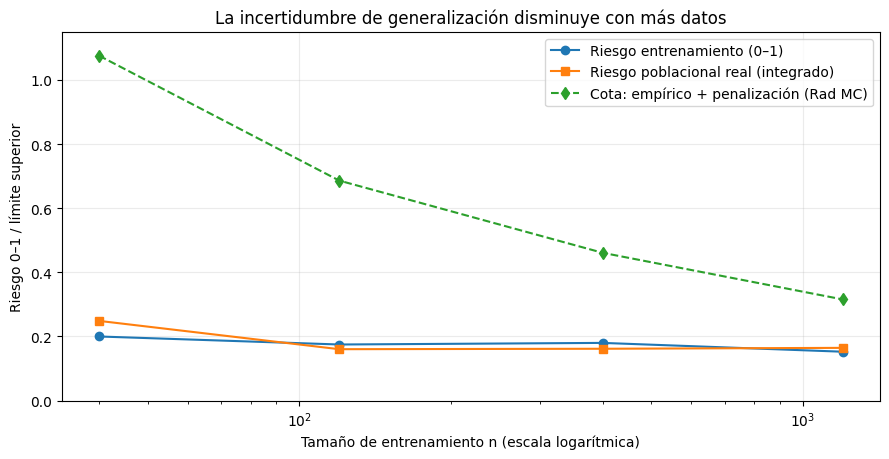

In [ ]:
# Creamos una figura que comparará riesgo empírico, verdadero y cota aproximada.
plt.figure()
# Dibujamos el error de entrenamiento para cada tamaño muestral.
plt.plot(tabla_cota['n'], tabla_cota['Riesgo empírico'], 'o-', label='Riesgo entrenamiento (0–1)')
# Dibujamos el error poblacional verdadero, calculado por integración numérica.
plt.plot(tabla_cota['n'], tabla_cota['Riesgo verdadero'], 's-', label='Riesgo poblacional real (integrado)')
# Dibujamos la cota ilustrativa que incluye una penalización de complejidad.
plt.plot(tabla_cota['n'], tabla_cota['Cota ilustrativa'], 'd--', label='Cota: empírico + penalización (Rad MC)')
# Usamos un eje horizontal logarítmico para representar n muy distintos.
plt.xscale('log')
# Ajustamos el rango del eje de pérdidas para incluir valores algo mayores que 1.
plt.ylim(0, 1.15)
# Indicamos que n crece en escala logarítmica.
plt.xlabel('Tamaño de entrenamiento n (escala logarítmica)')
# Nombramos el riesgo 0–1 y el límite superior aproximado.
plt.ylabel('Riesgo 0–1 / límite superior')
# El título conecta datos más abundantes con menor penalización de generalización.
plt.title('La incertidumbre de generalización disminuye con más datos')
# Añadimos la leyenda y mostramos las curvas.
plt.legend(); plt.tight_layout(); plt.show()

**Cómo leer la figura:**

- La diferencia entre riesgo de entrenamiento y riesgo real es la **brecha de generalización**; puede ser positiva o negativa para un conjunto concreto.
- La cota es deliberadamente conservadora, a veces mayor que 1 y por ello vacua. Que sea alta **no demuestra** que el clasificador sea malo.
- Un nivel $1-\delta=95\%$ habla de la **probabilidad sobre futuras muestras completas de entrenamiento** de que la desigualdad valga simultáneamente para todos los candidatos, bajo sus supuestos. No significa que el individuo tenga 95% de probabilidad de recibir una predicción correcta.
- Esta sección cuantifica **incertidumbre estadística sobre rendimiento esperado**, no variabilidad intrínseca de $Y\mid X=x$.

## 6. Tres conceptos distintos de incertidumbre

**1. Aleatoria / aleatoria irreducible (*aleatoric*).** Aunque conozcamos el mecanismo verdadero, el resultado varía. Para una etiqueta Bernoulli de probabilidad $p^*(x)$, su varianza condicional es $p^*(x)(1-p^*(x))$: máxima cerca de $p^*=0.5$.

**2. Epistémica (falta de conocimiento del modelo).** El modelo podría cambiar si observáramos otros ejemplos. Aproximaremos la **inestabilidad por muestreo del algoritmo** con bootstrap. No es una medida universal o completa de incertidumbre epistémica: el sesgo del modelo y la estrategia de remuestreo pueden ocultarla.

**3. De generalización.** Qué tanto puede diferir el riesgo en población del observado en entrenamiento. Las cotas de VC/Rademacher tratan principalmente esta tercera cuestión.

Estas cantidades tienen objetivos distintos. En particular, un predictor puede tener baja complejidad de Rademacher y, sin embargo, estar sistemáticamente mal especificado o mal calibrado.

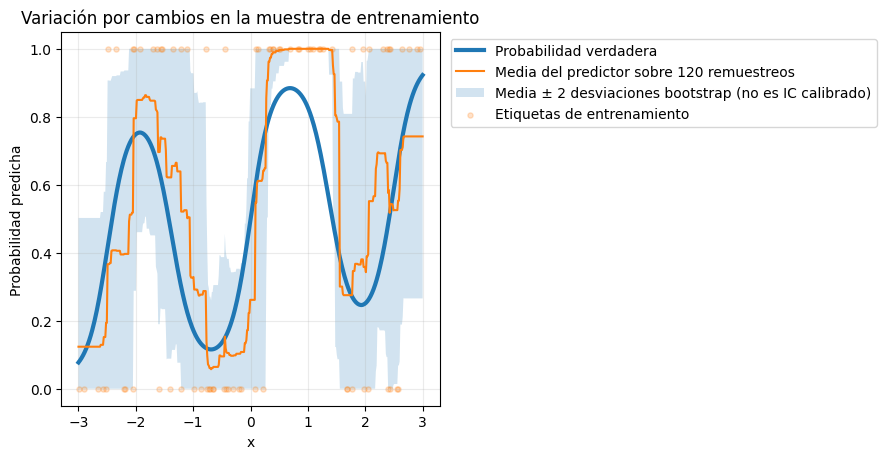

In [ ]:
# Generamos otra muestra de entrenamiento para estudiar variabilidad entre ajustes.
x_b, y_b = generar_datos(78, np.random.default_rng(980))
# Creamos 450 posiciones donde evaluaremos las probabilidades predichas.
grid_b = np.linspace(-3, 3, 450)
# Haremos 120 remuestreos bootstrap del conjunto de entrenamiento.
B = 120
# Inicializamos un generador fijo para seleccionar remuestreos reproducibles.
rng_b = np.random.default_rng(981)
# Aquí guardaremos una curva de probabilidad por cada modelo remuestreado.
predicciones_boot=[]
# Entrenamos un nuevo árbol para cada remuestreo.
for b in range(B):
    # Elegimos con reemplazo el mismo número de observaciones que en la muestra original.
    idx = rng_b.integers(0, len(x_b), size=len(x_b))
    # Usamos un árbol regularizado con profundidad 4 y al menos cinco ejemplos por hoja.
    model_b = DecisionTreeClassifier(max_depth=10, min_samples_leaf=5, random_state=b)   #MODIFICADO
    # Ajustamos el árbol sobre la muestra bootstrap indexada por idx.
    model_b.fit(x_b[idx].reshape(-1,1), y_b[idx])
    # Consideramos el caso excepcional de que un remuestreo contenga una sola clase.
    # Manejar incluso el evento raro de bootstrap con una sola clase.
    # Verificamos si el árbol solo conoce una clase.
    if len(model_b.classes_) == 1:
        # En ese caso, predice 0 o 1 con probabilidad uno para todo el dominio.
        p_b = np.full(len(grid_b), float(model_b.classes_[0]))
    # Si hay dos clases, obtenemos explícitamente la columna correspondiente a clase 1.
    else:
        # Buscamos el índice de la etiqueta 1 dentro del orden de clases del árbol.
        columna_1 = np.flatnonzero(model_b.classes_ == 1)[0]
        # Extraemos P(Y=1|x) sobre los 450 puntos de la malla.
        p_b = model_b.predict_proba(grid_b.reshape(-1,1))[:, columna_1]
    # Agregamos la curva de probabilidad de este remuestreo al conjunto.
    predicciones_boot.append(p_b)
# Convertimos la lista de curvas en una matriz (remuestreos × posiciones).
preds_boot = np.asarray(predicciones_boot)
# Promediamos las probabilidades predichas de todos los árboles en cada posición.
media_boot = preds_boot.mean(axis=0)
# Medimos cuánto varían esas predicciones entre distintos remuestreos.
sd_boot = preds_boot.std(axis=0)

# Iniciamos la figura del experimento bootstrap.
plt.figure()
# Dibujamos la probabilidad verdadera para tener una referencia conocida.
plt.plot(grid_b, prob_real(grid_b), linewidth=3, label='Probabilidad verdadera')
# Dibujamos la curva promedio del conjunto de modelos bootstrap.
plt.plot(grid_b, media_boot, label='Media del predictor sobre 120 remuestreos')
# Dibujamos una banda alrededor de la media: media menos dos desviaciones.
plt.fill_between(grid_b, np.clip(media_boot-2*sd_boot, 0, 1),
                 # El extremo superior es media más dos desviaciones; recortamos al intervalo [0,1].
                 np.clip(media_boot+2*sd_boot, 0, 1), alpha=.2,
                 # La banda describe dispersión bootstrap; NO es un intervalo de confianza calibrado.
                 label='Media ± 2 desviaciones bootstrap (no es IC calibrado)')
# Mostramos los ejemplos originales como puntos transparentes.
plt.scatter(x_b, y_b, s=14, alpha=.22, label='Etiquetas de entrenamiento')
# Escribimos los nombres de los dos ejes.
plt.xlabel('x'); plt.ylabel('Probabilidad predicha')
# El título enfatiza cambios debidos a variaciones en la muestra de entrenamiento.
plt.title('Variación por cambios en la muestra de entrenamiento')
# Colocamos leyenda fuera del área de datos y mostramos la figura.
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

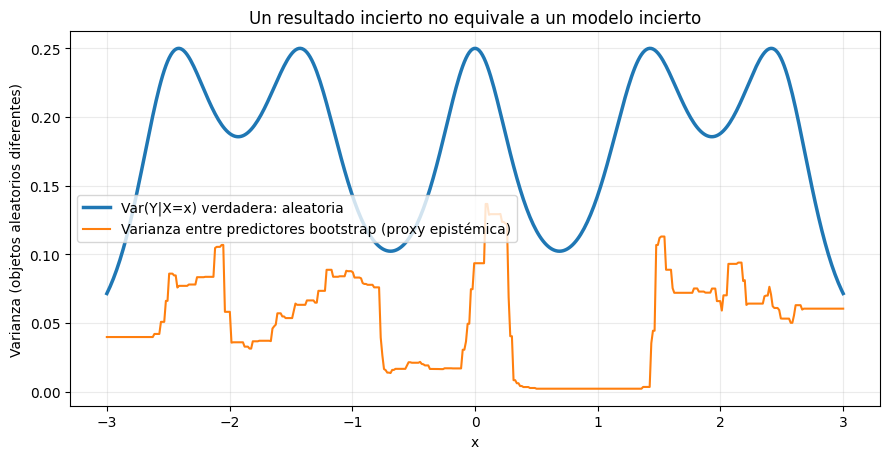

In [ ]:
# Calculamos varianza Bernoulli p(x)*(1-p(x)): incertidumbre aleatoria irreducible.
var_aleatoria = prob_real(grid_b)*(1-prob_real(grid_b))
# Calculamos la varianza de las predicciones entre remuestreos: proxy de incertidumbre epistémica.
var_boot = preds_boot.var(axis=0)
# Creamos una figura nueva.
plt.figure()
# Dibujamos la varianza del resultado Y condicionada al valor x.
plt.plot(grid_b, var_aleatoria, linewidth=2.5,
         # Esta continuación nombra la incertidumbre asociada al propio resultado aleatorio.
         label='Var(Y|X=x) verdadera: aleatoria')
# Dibujamos la variación entre predictores ajustados en remuestreos distintos.
plt.plot(grid_b, var_boot, label='Varianza entre predictores bootstrap (proxy epistémica)')
# Indicamos que ambas curvas son varianzas, pero de objetos aleatorios diferentes.
plt.xlabel('x'); plt.ylabel('Varianza (objetos aleatorios diferentes)')
# El título recuerda que ambigüedad del resultado y desconocimiento del modelo no son iguales.
plt.title('Un resultado incierto no equivale a un modelo incierto')
# Mostramos la leyenda y la gráfica.
plt.legend(); plt.tight_layout(); plt.show()

### 6.1 La calibración tampoco se deduce de una cota VC/Rademacher

Si un predictor emite $p=0.8$ para muchos casos semejantes, deseamos que alrededor de 80% sean positivos. Una **curva de calibración** agrupa predicciones y compara frecuencia real con probabilidad pronosticada. La diagonal es calibración perfecta; un modelo más flexible no tiene por qué estar mejor calibrado.

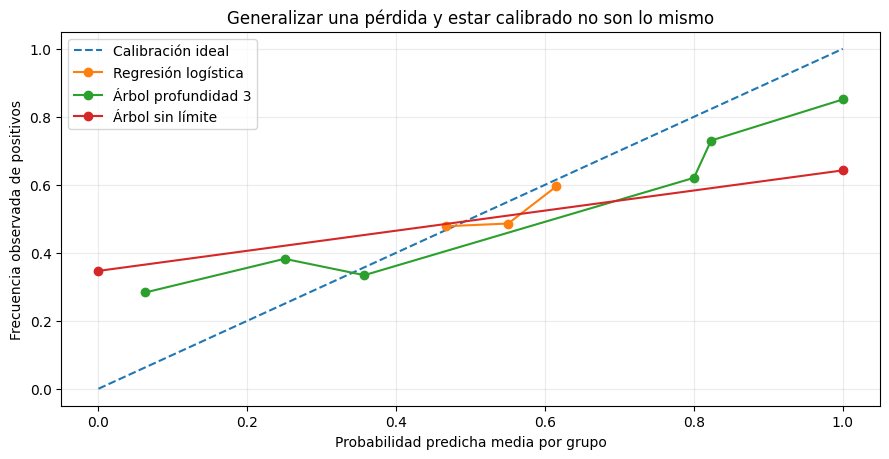

In [ ]:
# Ajustamos una regresión logística usando la misma muestra de entrenamiento.
logistica = LogisticRegression(random_state=2).fit(x_train.reshape(-1,1), y_train)
# Creamos un diccionario de modelos para contrastar sus calibraciones.
calibrables = {
    # Incluimos un clasificador logístico con frontera lineal en el logit.
    'Regresión logística': logistica,
    # Incluimos un árbol moderadamente flexible.
    'Árbol profundidad 3': modelos['Árbol profundidad 3'],
    # Incluimos un árbol sin límite de profundidad que puede sobreajustar.
    'Árbol sin límite': modelos['Árbol sin límite'],
}
# Abrimos una figura para la curva de calibración.
plt.figure()
# Dibujamos la diagonal ideal: predicción media y frecuencia observada coinciden.
plt.plot([0,1], [0,1], '--', label='Calibración ideal')
# Recorremos los tres modelos por su nombre.
for nombre, mod in calibrables.items():
    # Calculamos sus probabilidades de clase 1 en los 10 000 ejemplos de prueba.
    probabilidades = mod.predict_proba(x_test.reshape(-1,1))[:,1]
    # Dividimos probabilidades en 10 intervalos y obtenemos frecuencia real y promedio predicho.
    frec, pred = calibration_curve(y_test, probabilidades, n_bins=10, strategy='uniform')
    # Colocamos los puntos (probabilidad predicha media, frecuencia observada).
    plt.plot(pred, frec, 'o-', label=nombre)
# Nombramos el promedio de las probabilidades predichas.
plt.xlabel('Probabilidad predicha media por grupo')
# Nombramos la fracción de etiquetas positivas realmente observadas.
plt.ylabel('Frecuencia observada de positivos')
# El título distingue la calidad de calibración de las cotas de generalización.
plt.title('Generalizar una pérdida y estar calibrado no son lo mismo')
# Mostramos leyenda y figura.
plt.legend(); plt.tight_layout(); plt.show()

## 7. Práctica final guiada

Modifica **una variable a la vez** y vuelve a ejecutar la celda correspondiente:

1. En el apartado **1.2**, eleva el ruido de etiquetas de `0.07` a `0.30`. ¿El intervalo sigue superando al umbral? ¿Una diferencia de VC de una unidad garantiza algo por sí sola?
2. En el apartado **2.1**, cambia los datos repetidos por **cuatro** valores distintos repetidos dos veces. ¿Cómo cambia la Rademacher empírica? Explica por qué VC de la clase no cambió.
3. En el apartado **3**, cambia `n=72` por `n=400`. ¿Se reduce la brecha de Brier del árbol complejo? ¿Puede empeorar igualmente la calibración?
4. En el apartado **5**, experimenta con $\delta=0.20$ y $\delta=0.01$. ¿Cuál es más exigente? ¿Qué ocurre con el término $\sqrt{\log(2/\delta)/(2n)}$?
5. En el apartado **6**, modifica la profundidad del árbol bootstrap. ¿Qué parte de la figura cambia: la varianza intrínseca, la inestabilidad del algoritmo o ambas?

### Autoevaluación matemática

**A.** ¿Qué contraejemplo prueba que los intervalos en una recta no fragmentan tres puntos?

**B.** Si una clase reproduce los $2^n$ etiquetados posibles en los $n$ puntos observados, ¿cuánto vale su complejidad de Rademacher empírica para predicciones $\pm1$?

**C.** ¿Qué cota controla el término de generalización: la Rademacher de $\mathscr H$ o la de $\ell\circ\mathscr H$?

**D.** ¿Tener una cota de riesgo con $\delta=0.05$ implica que una predicción $p=0.9$ está calibrada? Explica.

**E.** ¿Por qué una pérdida logarítmica sin restricción de probabilidades no puede introducirse sin más en una desigualdad que exige pérdidas en $[0,1]$?

**RESPUESTAS A PRACTICA 1**

Alumno: Ortiz Perez Brandon Alexis


 **1.¿El intervalo sigue superando al umbral?**
Si, el intervalo sigue teniendo menor error que el umbral, porque la regla real de los datos digue teniendo forma de intervalo (-.85, .85) y un umbral simple nunca puede cerrar el lado derecho. Sin embargo, la diferencia entre ambos se achica muchidimo: mientras con 7% de ruido ek intervalo casi no fallaba con 30% de ruido se degrada bastante y empieza a recorrer sus bordes hacia adentro tratando de ajustarse a los puntos ruidosos.

**¿Una diferencia de VC de una unidad garantiza algo por sí sola?**
No, por si sola no garantiza un mejor desempeño ni una mejor generalizacion. Tener VC=2 en lugar de VC=1 unicamente indica q ue el modelo tiene poco mas de flexibilidad, pero dicho factor ayude depende de si la estructura del modelo encaja con el problema real y del nivel de ruido: si hay demasiado ruido esa capacidad extra se desperdicia intentando memorizar errores aleatoriosen vez de recuperar la frontera verdadera.


**2.¿Cómo cambia la Rademacher empírica? Explica por qué VC de la clase no cambió.**
la comolejidad de rademacher aumenta en las tres clases, esto ocurre porque al tener 4 entradas distintas en lugar de 2, las hipotesis tienen mas grados de libertad para asignar etiquetas diferentes y ajustarse mejor al ruido aleatorio, aunque siguen estando por debajo del caso con 8 valores distintos y porque cada par de puntos identicos sigue obligado a recibir exactamente la misma prediccion.
Al modificar x_repetidos para pasar de 2 valores distintos repetidos a 4 valores distintos repetidos dos veces, la primera columna (8 valores distintos) se mantiene igual (0.4561, 0.6680 y 1.0000), mientras que en la columna de datos repetidos la Rademacher empírica aumenta en las tres clases: el Umbral sube de 0.3242 a 0.3652, el Intervalo de 0.3750 a 0.4746 y las Funciones libres de 0.3750 a 0.5000. Esto pasa porque al haber 4 entradas únicas en lugar de 2, las funciones tienen más flexibilidad para separar puntos y ajustarse al ruido aleatorio, aunque siguen sin alcanzar los valores de la primera columna porque los puntos repetidos siguen forzados a tener la misma predicción.

**3.¿Se reduce la brecha de Brier del árbol complejo?**
No, sigue siendo muy grande. Como el Árbol sin límite no tiene restricción de profundidad, se memoriza todos los puntos nuevos. En entrenamiento su error sigue siendo casi cero, pero al probarlo con datos nuevos se equivoca mucho porque está sobreajustado (overfitting), así que la diferencia entre entrenamiento y prueba no se arregla.
**¿Puede empeorar igualmente la calibración?**
Sí, de hecho se nota mucho en la segunda gráfica. La probabilidad real es suave y tiene valores intermedios, pero el árbol complejo solo sabe dar respuestas extremas: 0 o 1. Al darle 400 datos en lugar de 72, el árbol hace muchísimos más cortes saltando de 0 a 1 todo el tiempo para seguir el ruido, lo que hace que sus probabilidades estimadas estén muy mal calibradas.

**4.¿Cuál es más exigente?**
El valor con Delta igual a 0.01 es más exigente, usar 0.01 significa exigir que la cota se cumpla con un 99% de seguridad, sólo 1% de margen de fallo, mientras que al usar el valor de 0.20 se pide un 80% de confianza.

**¿que ocurre con la expresion señalada?**
Al bajar 0.20 a cero a 0.01. La división 2/delta se hace más grande y el término retante aumenta. en las tablas se ve directo cuando Delta es igual a 0.20. La penalización para N igual a 40 es 0.74 05, pero al exigir Delta igual a 0.01 sube hasta 1.0036, como se pide más confianza la fórmula amplía el margen de seguridad y la cuota sube.

**5.¿Qué parte de la figura cambia: la varianza intrínseca, la inestabilidad del algoritmo o ambas?**
la que sí cambia es la inestabilidad del algoritmo, porque esa inestabilidad es que tanto cambian las predicciones cuando le damos muestras ligeramente distintas y la varianza intrínseca no cambia porque la naturaleza de los datos es la misma en las tres gráficas. El ruido del problema no depende de cómo configuremos el árbol.

**AUTOEVALUACION MATEMATICA**

**¿qué contra ejemplo, prueba que los intervalos en una recta no fragmentan tres puntos?** el contraejemplo es la asigancion de etiquetas y=1, x=0, z=1 ya que nigun intervalo puede separar los extremos del punto del medio.
de forma equivalente con etiquetas +,-,+


**B. Si una clase reproduce los  2n  etiquetados posibles en los  n  puntos observados, ¿cuánto vale su complejidad de Rademacher empírica para predicciones  ±1 ?**
Su complejidad de rademacher empirica vale 1.

**C. ¿Qué cota controla el término de generalización: la Rademacher de $\mathscr H$ o la de $\ell\circ\mathscr H$?**
la cota controla el termino de generalizacion a traves de la complejidad de rademacher de la clase de perdidas aunque posteriormente se acote usanso la de H

**D.¿Tener una cota de riesgo con $\delta=0.05$ implica que una predicción $p=0.9$ está calibrada? Explica.**
No, ya que miden dos cosas completamente distintas.

La cota de riesgo habla del error promedio en toda la poblacion, si delta es igual a 0.5 garantiza con un 95% de probabilidad que el riesgo verdadero del modelo no superara cierto limte superior.

La calibracion habla de la frecuencia real por grupo de predicciones exige que entre todos los casos donde el modelo predice 0.9, el evento positivo ocurra realmente alrededor del 90% de las veces.


**E. ¿Por qué una pérdida logarítmica sin restricción de probabilidades no puede introducirse sin más en una desigualdad que exige pérdidas en  [0,1] ?**
porque la perdida logaritmica no esta acotada superiormente: si un modelo predice p=0 o un valor extremadamente cercano a cero cuaando la etiqueta real es y=1, la perdida -log(p) tiende a infinito rompiendo el requisito de pertenecer al intervalo [0,1]

## 8. Mapa conceptual y fórmulas para recordar

| Concepto | Pregunta que responde | Depende de | Qué **no** responde |
|:---|:---|:---|:---|
| **Dimensión VC** | ¿Cuántos puntos puede fragmentar la clase en el mejor caso? | Familia de hipótesis | El error que tendrá un ajuste concreto |
| **Rademacher empírica** | ¿Cuánto ruido aleatorio puede ajustar la clase sobre estas entradas? | Familia y entradas de la muestra | Si las etiquetas reales son predecibles |
| **Riesgo empírico** | ¿Qué pérdida obtuvo el modelo en los datos vistos? | Modelo, datos y pérdida | Su riesgo verdadero, por sí solo |
| **Cota de generalización** | ¿Qué tan mayor podría ser el riesgo poblacional bajo ciertos supuestos? | Complejidad de la clase de pérdidas, $n$, $\delta$ | Probabilidad correcta de cada predicción |
| **Incertidumbre aleatoria** | ¿Qué variación queda incluso conociendo $P(Y\mid X)$? | Proceso generador | Qué tan bien conocemos el modelo |
| **Incertidumbre epistémica** | ¿Qué desconocimiento o inestabilidad queda al estimar? | Datos, supuestos y método | Una garantía universal usando solo bootstrap |

### Cadena lógica central

$$
\boxed{\text{VC} \ \longrightarrow\ \text{patrones que la clase puede realizar}
\ \longrightarrow\ \text{Rademacher}}
$$
$$
\boxed{\text{Rademacher de las pérdidas} + n +\delta
\ \longrightarrow\ \text{cota para riesgo verdadero}}
$$

**Advertencia fundamental:** el entrenamiento y la evaluación deben corresponder a un problema de muestras i.i.d. para aplicar directamente las cotas mostradas; datos temporales, cambio de distribución, dependencias, modelos elegidos después de ver la evaluación o valores de pérdida no acotados exigen análisis adicional.